# Practical 10: Case Study - Credit Card Fraud Detection


Upon completion of this session you should be able to:
- understand how to test different methods on skewed data.
- be able to apply cross validation and hyperparameter tuning in Python.

---
- Materials in this module include resources collected from various open-source online repositories.
- Jupyter source file can be downloaded from https://github.com/gaoshangdeakin/SIT384-Jupyter
- If you found any issue/bug for this document, please submit an issue at [https://github.com/gaoshangdeakin/SIT384/issues](https://github.com/gaoshangdeakin/SIT384/issues)


---


This practical will test different methods on skewed data. The idea is to compare if preprocessing techniques work better when there is an overwhelming majority class that can disrupt the efficiency of our predictive model.

You will also be able to see how to apply cross validation for hyperparameter tuning on different classification models. The intention is to create models using:

1. Logistic Regression


## Background

## Tasks

## Summary


In [1]:
from __future__ import division
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

# <span style="color:#0b486b">Loading the dataset</span>

In [2]:
#The zipped data file can be retrieved from the weekly folder on clouddeakin. Not available on unit github site due to size restriction (max 25M)
data = pd.read_csv("./creditcard.csv")
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# <span style="color:#0b486b">Checking the target classes</span>

Class
0    284315
1       492
Name: count, dtype: int64


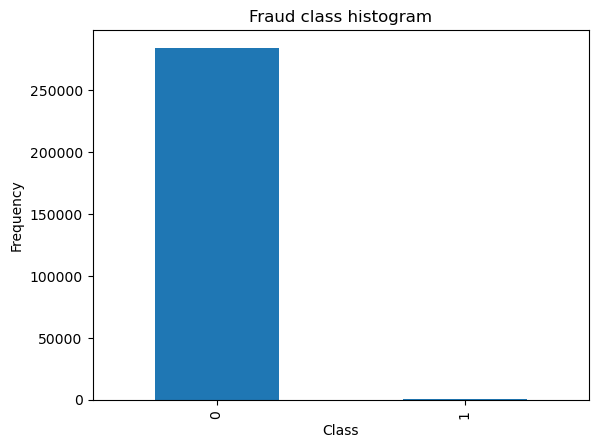

In [22]:
#count_classes = pd.value_counts(data['Class'], sort = True).sort_index() #commented out by Shang 11/05/2025 due to 
#pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
count_classes = pd.Series(data['Class']).value_counts(sort=True).sort_index()
count_classes.plot(kind = 'bar')
plt.title("Fraud class histogram")
plt.xlabel("Class")
plt.ylabel("Frequency")
print(count_classes)

### Clearly the data is totally unbalanced!! 

This is a clear example where using a typical accuracy score is not appropriate for evaluating our classification algorithm. For example, if we just used a majority class to assign values to all records, we will still be having a high accuracy, BUT WE WOULD BE CLASSIFYING ALL "1" INCORRECTLY!!

There are several ways to approach this classification problem taking into consideration this imbalance. 

- Collect more data? Nice strategy but not applicable in this case
- Changing the performance metric:
    - Use the confusion matrix to calculate Precision, Recall
    - F1score (weighted average of precision recall)
    - Use Kappa - which is a classification accuracy normalized by the imbalance of the classes in the data
    - ROC curves - calculates sensitivity/specificity ratio.
- Resampling the dataset
    - Essentially this is a method that will process the data to have an approximate 50-50 ratio.
    - One way to achieve this is by OVER-sampling, which is adding copies of the under-represented class (better when you have little data)
    - Another is UNDER-sampling, which deletes instances from the over-represented class (better when you have lot's of data)

# <span style="color:#0b486b">Approach</span>

1. We are not going to perform feature engineering in first instance. The dataset has been downgraded in order to contain 30 features (28 anonamised + time + amount). 
2. We will compare what happens when using resampling and when not using it. We will test this approach using a simple logistic regression classifier.
3. We will evaluate the models by using some of the performance metrics mentioned above.
4. We will repeat the best resampling/not resampling method, by tuning the parameters in the logistic regression classifier.
5. We will finally perform classifications model using other classification algorithms for comparison. We will leave it for your homework.

# <span style="color:#0b486b">Setting our input and target variables + resampling</span>

#### 1. Normalising the amount column. The amount column is not in line with the anonimised features.

In [4]:
from sklearn.preprocessing import StandardScaler
data['normAmount'] = StandardScaler().fit_transform(data['Amount'].values.reshape(-1, 1))
data = data.drop(['Time','Amount'],axis=1)
data.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Class,normAmount
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0,0.244964
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0,-0.342475
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0,1.160686
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0,0.140534
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0,-0.073403


#### 2. Resampling.

- As we mentioned earlier, there are several ways to resample skewed data. Apart from under and over sampling, there is a very popular approach called SMOTE (Synthetic Minority Over-Sampling Technique), which is a combination of oversampling and undersampling, but the oversampling approach is not by replicating minority class but constructing new minority class data instance via an algorithm. Note: SMOTE should only be applied to the training data, not test data.

- In this practical, we will use traditional UNDER-sampling.

- The way we will under sample the dataset by creating a 50/50 ratio. This will be done by randomly selecting "x" amount of sample from the majority class, being "x" the total number of records with the minority class.

In [5]:
X = data.iloc[:, data.columns != 'Class']
y = data.iloc[:, data.columns == 'Class']

In [6]:
# Number of data points in the minority class
number_records_fraud = len(data[data.Class == 1])
fraud_indices = np.array(data[data.Class == 1].index)

# Picking the indices of the normal classes
normal_indices = data[data.Class == 0].index

# Out of the indices we picked, randomly select "x" number (number_records_fraud)
random_normal_indices = np.random.choice(normal_indices, number_records_fraud, replace = False)
random_normal_indices = np.array(random_normal_indices)

# Appending the 2 indices
under_sample_indices = np.concatenate([fraud_indices,random_normal_indices])

# Under sample dataset
under_sample_data = data.iloc[under_sample_indices,:]

X_undersample = under_sample_data.iloc[:, under_sample_data.columns != 'Class']
y_undersample = under_sample_data.iloc[:, under_sample_data.columns == 'Class']

# Showing ratio
print("Percentage of normal transactions: ", len(under_sample_data[under_sample_data.Class == 0])/float(len(under_sample_data)))
print("Percentage of fraud transactions: ", len(under_sample_data[under_sample_data.Class == 1])/float(len(under_sample_data)))
print("Total number of transactions in resampled data: ", len(under_sample_data))

Percentage of normal transactions:  0.5
Percentage of fraud transactions:  0.5
Total number of transactions in resampled data:  984


# <span style="color:#0b486b">Splitting data into train and test set. Cross validation will be used when calculating accuracies</span>

In [7]:
from sklearn.model_selection import train_test_split

# split whole dataset into train set and test set
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.3, random_state = 0)

print("Number transactions whole train dataset: ", len(X_train))
print("Number transactions whole test dataset: ", len(X_test))
print("Total number of whole transactions: ", len(X_train)+len(X_test))


# Undersampled dataset
X_train_undersample, X_test_undersample, y_train_undersample, y_test_undersample = train_test_split(X_undersample
                                                                                                   ,y_undersample
                                                                                                   ,test_size = 0.3
                                                                                                   ,random_state = 0)
print("")
print("Number transactions undersample train dataset: ", len(X_train_undersample))
print("Number transactions undersample test dataset: ", len(X_test_undersample))
print("Total number of undersample transactions: ", len(X_train_undersample)+len(X_test_undersample))



Number transactions whole train dataset:  199364
Number transactions whole test dataset:  85443
Total number of whole transactions:  284807

Number transactions undersample train dataset:  688
Number transactions undersample test dataset:  296
Total number of undersample transactions:  984


# <span style="color:#0b486b">Logistic regression classifier - Undersampled data</span>

We are very interested in the recall score, because that is the metric that will help us try to capture the most fraudulent transactions. If you think how Accuracy, Precision and Recall work for a confusion matrix, recall would be the most interesting:

- Accuracy = (TP+TN)/total
- Precision = TP/(TP+FP)
- Recall = TP/(TP+FN)

As we know, due to the imbalacing of the data, many observations could be predicted as False Negatives, being that we predict a normal transaction, but it is in fact a fraudulent one. Recall captures this.
- Obviously, trying to increase recall, tends to come with a decrease of precision. However, in our case, if we predict that a transaction is fraudulent and turns out not to be, is not a massive problem compared to the opposite. 
- We could even apply a cost function when having FN and FP with different weights for each type of error, but let's leave that aside for now.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from sklearn.metrics import confusion_matrix,precision_recall_curve,auc,roc_auc_score,roc_curve,recall_score,classification_report 

Very ad-hoc function to print K_fold_scores

In [9]:
c_param_range = [0.01,0.1,1,10,100]

#print("# Tuning hyper-parameters for %s" % score)
print()

clf = GridSearchCV(LogisticRegression(solver='liblinear'), {"C": c_param_range}, cv=5, scoring='recall')
clf.fit(X_train_undersample,y_train_undersample.values.ravel())

print ("Best parameters set found on undersample train set:")
print()
print (clf.best_params_)

print ("Grid scores on undersample train set:")
means = clf.cv_results_['mean_test_score']
stds = clf.cv_results_['std_test_score']
for mean, std, params in zip(means, stds, clf.cv_results_['params']):
    print("%0.3f (+/-%0.03f) for %r"
          % (mean, std * 2, params))

print ("Detailed classification report:")
print ("The model is trained on the undersample train set.")
print ("The scores are computed on the undersample test set.")
y_true_undersample, y_pred_undersample = y_test_undersample, clf.predict(X_test_undersample)
print(classification_report(y_true_undersample, y_pred_undersample))
print()
#Please note we did not use test set to select the best params.


Best parameters set found on undersample train set:

{'C': 0.01}
Grid scores on undersample train set:
0.925 (+/-0.043) for {'C': 0.01}
0.910 (+/-0.072) for {'C': 0.1}
0.913 (+/-0.066) for {'C': 1}
0.913 (+/-0.076) for {'C': 10}
0.916 (+/-0.070) for {'C': 100}
Detailed classification report:
The model is trained on the undersample train set.
The scores are computed on the undersample test set.
              precision    recall  f1-score   support

           0       0.93      0.96      0.95       149
           1       0.96      0.93      0.94       147

    accuracy                           0.95       296
   macro avg       0.95      0.95      0.95       296
weighted avg       0.95      0.95      0.95       296




In [10]:
# Define a function to find the best hyper-parameter optimizing for recall
def print_gridsearch_scores(x_train_data,y_train_data):
    c_param_range = [0.01,0.1,1,10,100]

    clf = GridSearchCV(LogisticRegression(solver='liblinear'), {"C": c_param_range}, cv=5, scoring='recall')
    clf.fit(x_train_data,y_train_data.values.ravel())

    print ("Best parameters set found on development set:")
    print()
    print (clf.best_params_)

    print ("Grid scores on development set:")
    means = clf.cv_results_['mean_test_score']
    stds = clf.cv_results_['std_test_score']
    for mean, std, params in zip(means, stds, clf.cv_results_['params']):
        print ("%0.3f (+/-%0.03f) for %r" % (mean, std * 2, params))
        
    return clf.best_params_["C"]

In [11]:
best_c_undersample = print_gridsearch_scores(X_train_undersample,y_train_undersample)

Best parameters set found on development set:

{'C': 0.01}
Grid scores on development set:
0.925 (+/-0.043) for {'C': 0.01}
0.910 (+/-0.072) for {'C': 0.1}
0.913 (+/-0.066) for {'C': 1}
0.913 (+/-0.076) for {'C': 10}
0.916 (+/-0.070) for {'C': 100}


Create a function to plot a fancy confusion matrix

In [12]:
import itertools

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=0)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        #print("Normalized confusion matrix")
    else:
        1#print('Confusion matrix, without normalization')

    #print(cm)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

### Predictions on test set and plotting confusion matrix

We have been talking about using the recall metric as our proxy of how effective our predictive model is. Even though recall is still the recall we want to calculate, just bear in mind that the undersampled data hasn't got a skewness towards a certain class, which doesn't make recall metric as critical. 

Recall metric in the testing dataset:  0.9319727891156463
[[136  13]
 [ 10 137]]


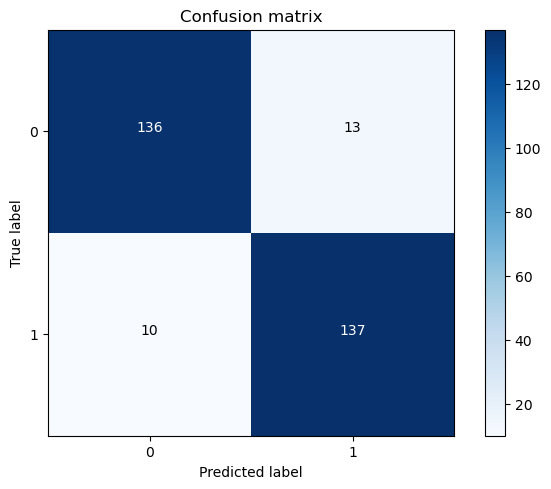

In [24]:
# Use this best C_parameter to build the final model with the undersample training dataset and 
#predict the classes in the undersample test dataset
lr = LogisticRegression(solver='liblinear', C = best_c_undersample, penalty = 'l1')
lr.fit(X_train_undersample,y_train_undersample.values.ravel())

#commented out by Shang due to warning:
#X does not have valid feature names, but LogisticRegression was fitted with feature names
#y_pred_undersample = lr.predict(X_test_undersample.values
y_pred_undersample = lr.predict(X_test_undersample)
                               

# Compute confusion matrix
cnf_matrix = confusion_matrix(y_test_undersample,y_pred_undersample)
np.set_printoptions(precision=2)

print("Recall metric in the testing dataset: ", cnf_matrix[1,1]/(cnf_matrix[1,0]+cnf_matrix[1,1]))
print(cnf_matrix)

# Plot non-normalized confusion matrix
class_names = [0,1]
plt.figure()
plot_confusion_matrix(cnf_matrix
                      , classes=class_names
                      , title='Confusion matrix')
plt.show()

So, the model is offering an 93% recall accuracy on the generalised unseen data (test set). Not a bad percentage to be the first try. However, remember this is a 93% recall accuracy measure on the undersampled test set.

Being happy with this result, let's apply the model we fitted and test it on the whole data.

Recall metric in the testing dataset:  0.5510204081632653
[[85284    12]
 [   66    81]]


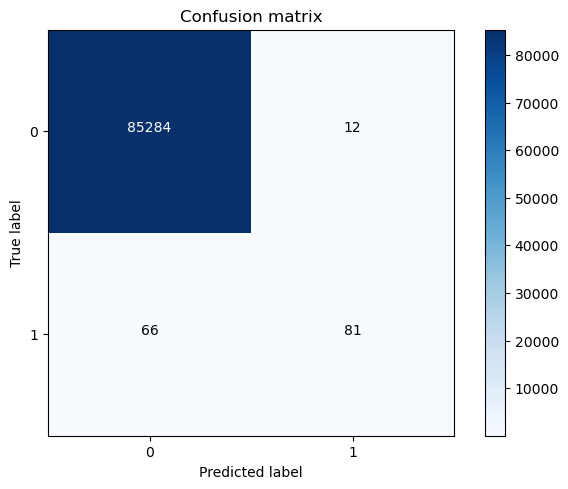

In [26]:
# Use this C_parameter to build the final model with the whole training dataset and 
#predict the classes in the whole test dataset
lr = LogisticRegression(solver='liblinear', C = best_c_undersample, penalty = 'l1')
lr.fit(X_train,y_train.values.ravel())

#commented out by Shang 11/05/2026, due to: 
#UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
#y_pred = lr.predict(X_test.values)
y_pred = lr.predict(X_test)

# Compute confusion matrix
cnf_matrix = confusion_matrix(y_test,y_pred)
np.set_printoptions(precision=2)

print("Recall metric in the testing dataset: ", cnf_matrix[1,1]/(cnf_matrix[1,0]+cnf_matrix[1,1]))
print(cnf_matrix)
# Plot non-normalized confusion matrix
class_names = [0,1]
plt.figure()
plot_confusion_matrix(cnf_matrix
                      , classes=class_names
                      , title='Confusion matrix')
plt.show()

Not a  decent recall accuracy at all when applying it to a much larger and skewed dataset! 

Seemed the initial approach is not working. We need to find the best hyperparameters for the whole skewed dataset. 

### Plotting ROC curve and Precision-Recall curve.

- We find precision-recall curve much more convenient in this case as our problems relies on the "positive" class being more interesting than the negative class, but as we have calculated the recall precision, we are not going to plot the precision recall curves yet.

- AUC and ROC curve are also interesting to check if the model is also predicting as a whole correctly and not making many errors

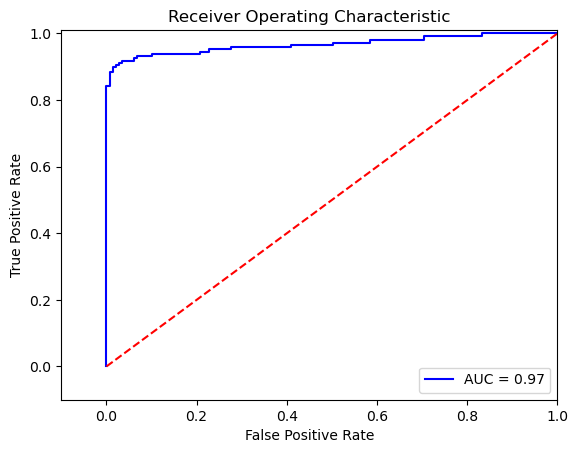

In [27]:
# ROC CURVE
lr = LogisticRegression(solver='liblinear', C = best_c_undersample, penalty = 'l1')
#y_pred_undersample_score = lr.fit(X_train_undersample,y_train_undersample.values.ravel()).decision_function(X_test_undersample.values)
y_pred_undersample_score = lr.fit(X_train_undersample,y_train_undersample.values.ravel()).decision_function(X_test_undersample)

fpr, tpr, thresholds = roc_curve(y_test_undersample.values.ravel(),y_pred_undersample_score)
roc_auc = auc(fpr,tpr)

# Plot ROC
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b',label='AUC = %0.2f'% roc_auc)
plt.legend(loc='lower right')
plt.plot([0,1],[0,1],'r--')
plt.xlim([-0.1,1.0])
plt.ylim([-0.1,1.01])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

An additional comment that would be interesting to do is to initialise multiple undersampled datasets and repeat the process in loop. Remember that, to create an undersample data, we randomly got records from the majority class. Even though this is a valid technique, it doesn't represent the real population, so it would be interesting to repeat the process with different undersample configurations and check if the previous chosen parameters are still the most effective. In the end, the idea is to use a wider random representation of the whole dataset and rely on the averaged best parameters.

# <span style="color:#0b486b">Logistic regression classifier - Skewed data</span>

Having tested our previous approach, we find really interesting to test the same process on the skewed data. Our intuition is that skewness will introduce issues difficult to capture, and therefore, provide a less effective algorithm.
- To be fair, taking into account the fact that the train and test datasets are substantially bigger than the undersampled ones, we believe a K-fold cross validation is necessary. let's take the same approach as before. 

In [16]:
best_c = print_gridsearch_scores(X_train,y_train)

Best parameters set found on development set:

{'C': 10}
Grid scores on development set:
0.591 (+/-0.121) for {'C': 0.01}
0.594 (+/-0.076) for {'C': 0.1}
0.612 (+/-0.106) for {'C': 1}
0.620 (+/-0.122) for {'C': 10}
0.620 (+/-0.122) for {'C': 100}


Recall metric in the testing dataset:  0.6190476190476191
[[85284    12]
 [   56    91]]


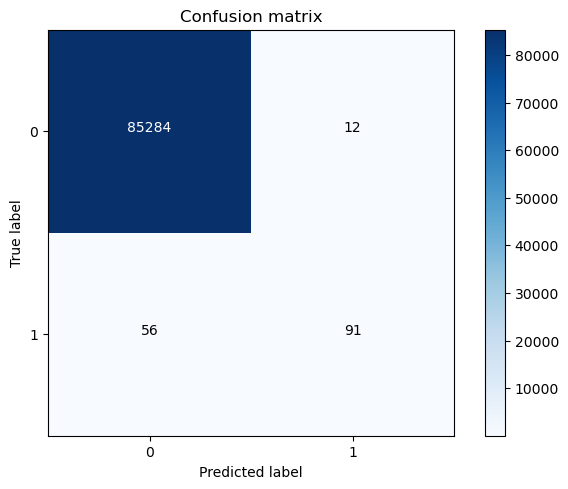

In [29]:
# Use this C_parameter to build the final model with the whole training dataset and 
#predict the classes in the test dataset
lr = LogisticRegression(solver='liblinear', C = best_c, penalty = 'l1')
lr.fit(X_train,y_train.values.ravel())
#y_pred = lr.predict(X_test.values)
y_pred = lr.predict(X_test)

# Compute confusion matrix
cnf_matrix = confusion_matrix(y_test,y_pred)
np.set_printoptions(precision=2)

print("Recall metric in the testing dataset: ", cnf_matrix[1,1]/(cnf_matrix[1,0]+cnf_matrix[1,1]))
print(cnf_matrix)

# Plot non-normalized confusion matrix
class_names = [0,1]
plt.figure()
plot_confusion_matrix(cnf_matrix
                      , classes=class_names
                      , title='Confusion matrix')
plt.show()

# <span style="color:#0b486b">Before continuing... changing classification threshold</span>

We have seen that by undersampling the data, our algorithm does a much better job at detecting fraud. We wanted also to show how can we tweak our final classification by changing the thresold.
- Initially, you build the classification model and then you predict unseen data using it.
- We previously used the "predict()" method to decided whether a record should belong to "1" or "0". 
- There is another method "predict_proba()".
    - This method returns the probabilities for each class. The idea is that by changing the threshold to assign a record to class 1, we can control precision and recall.
    
Let's check this using the undersampled data (best C_param)

Recall metric in the undersample testing dataset for threshold 0.1: 1.0
Recall metric in the undersample testing dataset for threshold 0.2: 1.0
Recall metric in the undersample testing dataset for threshold 0.3: 1.0
Recall metric in the undersample testing dataset for threshold 0.4: 0.9795918367346939
Recall metric in the undersample testing dataset for threshold 0.5: 0.9319727891156463
Recall metric in the undersample testing dataset for threshold 0.6: 0.8775510204081632
Recall metric in the undersample testing dataset for threshold 0.7: 0.8231292517006803
Recall metric in the undersample testing dataset for threshold 0.8: 0.7755102040816326
Recall metric in the undersample testing dataset for threshold 0.9: 0.5918367346938775


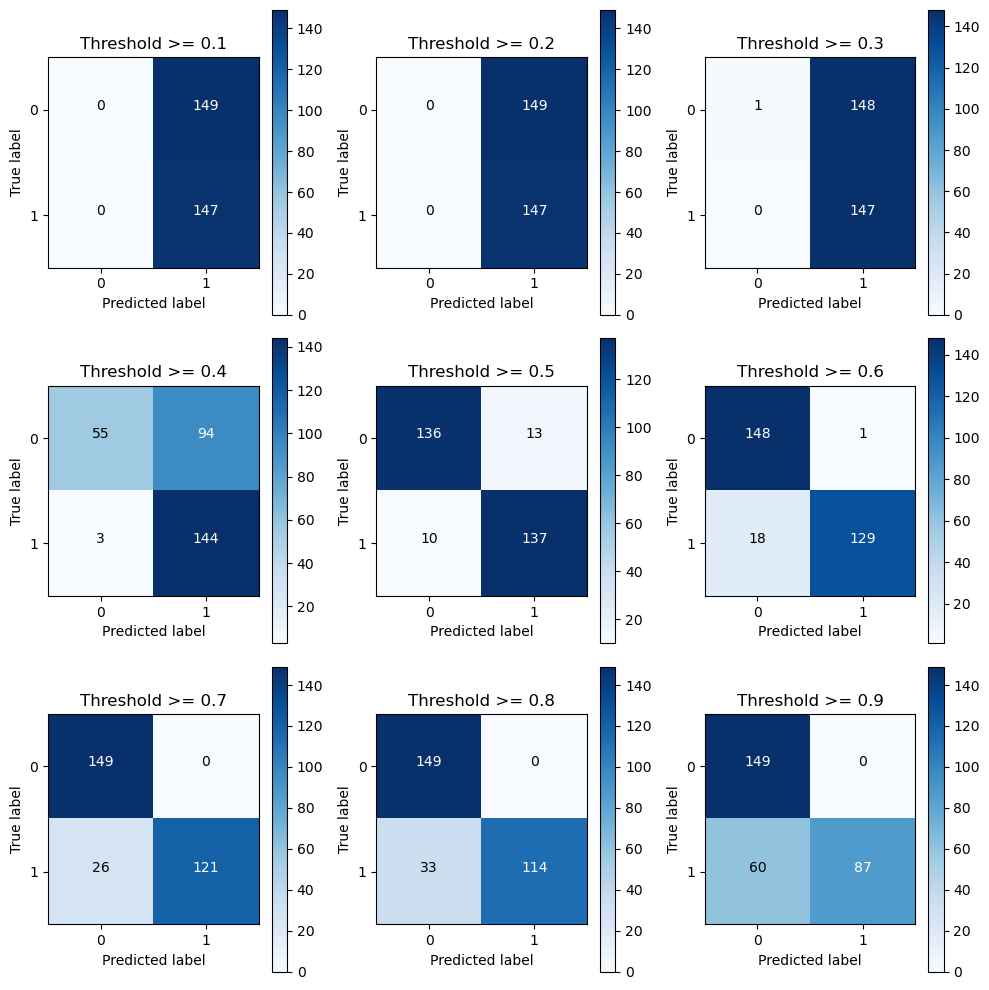

In [30]:
lr = LogisticRegression(solver='liblinear', C = best_c_undersample, penalty = 'l1')
lr.fit(X_train_undersample,y_train_undersample.values.ravel())
#y_pred_undersample_proba = lr.predict_proba(X_test_undersample.values)
y_pred_undersample_proba = lr.predict_proba(X_test_undersample)

thresholds = [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]

plt.figure(figsize=(10,10))

j = 1
for i in thresholds:
    y_test_predictions_high_recall = y_pred_undersample_proba[:,1] > i
    
    plt.subplot(3,3,j)
    j += 1
    
    # Compute confusion matrix
    cnf_matrix = confusion_matrix(y_test_undersample,y_test_predictions_high_recall)
    np.set_printoptions(precision=2)

    print ("Recall metric in the undersample testing dataset for threshold {}: {}".format(i, cnf_matrix[1,1]/(cnf_matrix[1,0]+cnf_matrix[1,1])))

    # Plot non-normalized confusion matrix
    class_names = [0,1]
    plot_confusion_matrix(cnf_matrix
                          , classes=class_names
                          , title='Threshold >= %s'%i) 

The pattern is very clear: the more you lower the required probability to put a certain in the class "1" category, more records will be put in that bucket.

This implies an increase in recall (we want all the "1"s), but at the same time, a decrease in precision (we misclassify many of the other class).

Therefore, even though recall is our goal metric (do not miss a fraud transaction), we also want to keep the model being accurate as a whole.

- There is an option we think could be quite interesting to tackle. We could assign cost to misclassifications, but being interested in classifying "1s" correctly, the cost for misclassifying "1s" should be bigger than "0" misclassifications. After that, the algorithm would select the threshold which minimises the total cost. A drawback we see is that we have to manually select the weight of each cost... therefore, we will leave this know as a thought.
- Going back to the threshold changing, there is an option which is the Precision-Recall curve. By visually seeing the performance of the model depending on the threshold we choose, we can investigate a sweet spot where recall is high enough whilst keeping a high precision value.

Investigate Precision-Recall curve and area under this curve.

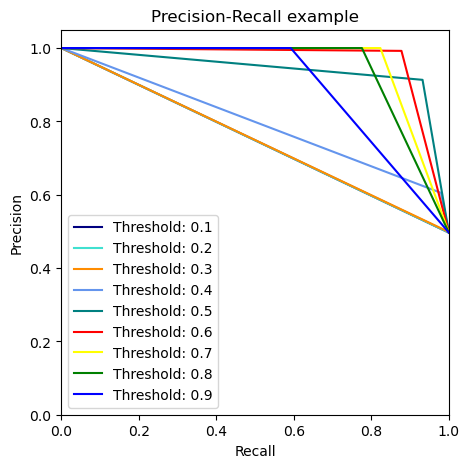

In [31]:
from itertools import cycle

lr = LogisticRegression(solver='liblinear', C = best_c_undersample, penalty = 'l1')
lr.fit(X_train_undersample,y_train_undersample.values.ravel())
#y_pred_undersample_proba = lr.predict_proba(X_test_undersample.values)
y_pred_undersample_proba = lr.predict_proba(X_test_undersample)

thresholds = [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]
colors = cycle(['navy', 'turquoise', 'darkorange', 'cornflowerblue', 'teal', 'red', 'yellow', 'green', 'blue','black'])

plt.figure(figsize=(5,5))

j = 1
for i,color in zip(thresholds,colors):
    y_test_predictions_prob = y_pred_undersample_proba[:,1] > i
    
    precision, recall, thresholds = precision_recall_curve(y_test_undersample,y_test_predictions_prob)
    
    # Plot Precision-Recall curve
    plt.plot(recall, precision, color=color,
                 label='Threshold: %s'%i)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.ylim([0.0, 1.05])
    plt.xlim([0.0, 1.0])
    plt.title('Precision-Recall example')
    plt.legend(loc="lower left")

We also wanted to show how we can tweak our final classification by changing the thresold for the whole skewed dataset.

Recall metric in the whole testing dataset for threshold 0.1: 0.7755102040816326
Recall metric in the whole testing dataset for threshold 0.2: 0.7414965986394558
Recall metric in the whole testing dataset for threshold 0.3: 0.6870748299319728
Recall metric in the whole testing dataset for threshold 0.4: 0.6462585034013606
Recall metric in the whole testing dataset for threshold 0.5: 0.6190476190476191
Recall metric in the whole testing dataset for threshold 0.6: 0.5918367346938775
Recall metric in the whole testing dataset for threshold 0.7: 0.5578231292517006
Recall metric in the whole testing dataset for threshold 0.8: 0.5238095238095238
Recall metric in the whole testing dataset for threshold 0.9: 0.4897959183673469


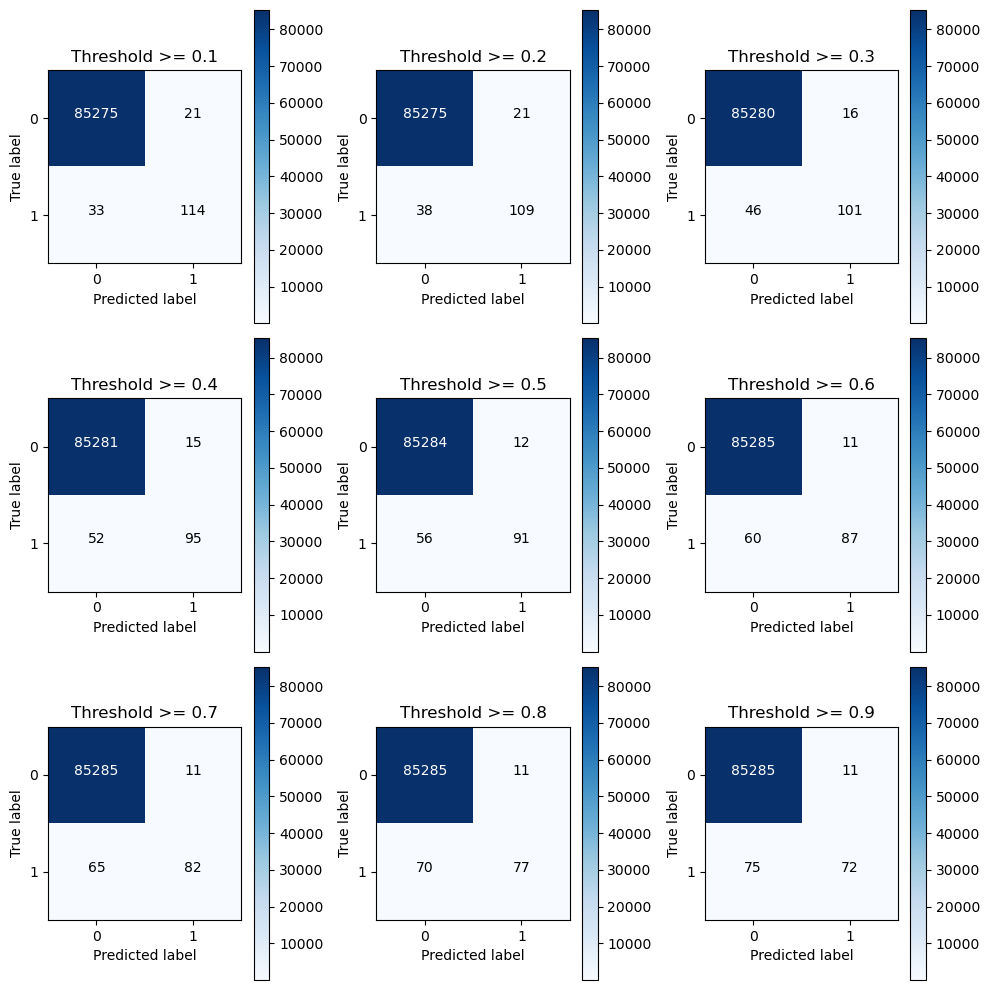

In [32]:
lr = LogisticRegression(solver='liblinear', C = best_c, penalty = 'l1')
lr.fit(X_train,y_train.values.ravel())
#y_pred_proba = lr.predict_proba(X_test.values)
y_pred_proba = lr.predict_proba(X_test)

thresholds = [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]

plt.figure(figsize=(10,10))

j = 1
for i in thresholds:
    y_test_predictions_high_recall = y_pred_proba[:,1] > i
    
    plt.subplot(3,3,j)
    j += 1
    
    # Compute confusion matrix
    cnf_matrix = confusion_matrix(y_test,y_test_predictions_high_recall)
    np.set_printoptions(precision=2)

    print ("Recall metric in the whole testing dataset for threshold {}: {}".format(i, cnf_matrix[1,1]/(cnf_matrix[1,0]+cnf_matrix[1,1])))

    # Plot non-normalized confusion matrix
    class_names = [0,1]
    plot_confusion_matrix(cnf_matrix
                          , classes=class_names
                          , title='Threshold >= %s'%i) 

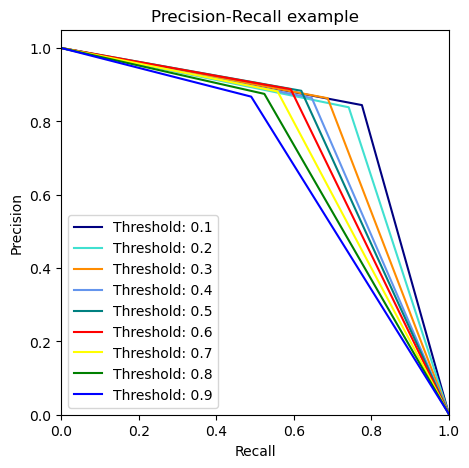

In [34]:
from itertools import cycle

lr = LogisticRegression(solver='liblinear', C = best_c, penalty = 'l1')
lr.fit(X_train,y_train.values.ravel())
#y_pred_proba = lr.predict_proba(X_test.values)
y_pred_proba = lr.predict_proba(X_test)

thresholds = [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]
colors = cycle(['navy', 'turquoise', 'darkorange', 'cornflowerblue', 'teal', 'red', 'yellow', 'green', 'blue','black'])

plt.figure(figsize=(5,5))

j = 1
for i,color in zip(thresholds,colors):
    y_test_predictions_prob = y_pred_proba[:,1] > i
    
    precision, recall, thresholds = precision_recall_curve(y_test,y_test_predictions_prob)
    
    # Plot Precision-Recall curve
    plt.plot(recall, precision, color=color,
                 label='Threshold: %s'%i)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.ylim([0.0, 1.05])
    plt.xlim([0.0, 1.0])
    plt.title('Precision-Recall example')
    plt.legend(loc="lower left")

The Logistic Regression fits well on the undersample dataset but the whole skewed dataset. We may try other classification models and compare the performance matrices before selecting the best for the skewed dataset.  

# <span style="color:#0b486b">Tasks</span>

Try the provided examples and get yourself familiar with sample code before attempting portolio tasks.

Please show your attempt to your tutor before you leave the lab, or email your files to your coordinator if you are an off-campus student.

# <span style="color:#0b486b">Summary</span>

In this session we have covered: 
 - how to apply different methods on skewed data.
 - how to apply cross-validation and tune hyperparameters in Python.

# <span style="color:#0b486b">Acknowledgement</span>

The above content references chapter 10 of "Hands-On Machine Learning for Cybersecurity: Safeguard your system by making your machines intelligent using the Python ecosystem", authored by Soma Halder, Sinan Ozdemir, Packt Publishing Ltd, 31 Dec 2018.  